# Evaluating MISB ST 1909 Burn-In Perturbations

```{warning}
[MISBST1909BurnInPerturber](<project:/development/experimental.rst#nrtk.impls.perturb_video.burn_in.MISBST1909BurnInPerturber>) is an experimental feature. Its API and behavior may change in future releases.
Enable it with `import nrtk.experimental` and install NRTK's `pillow` extra.
```

## Introduction
This notebook is part of the NRTK demonstration suite, demonstrating how perturbations can be applied and their impact measured via MAITE evaluation workflows.

## Layout
This notebook demonstrates how a particular condition (in this case, <b><i>MISB ST 1909 metadata burn-in</i></b>), can affect a multi-object tracking (MOT) model, and how that impact can be measured. The overall structure is:

- **Evaluation Guidance: Computing Higher Order Tracking Accuracy (HOTA):**
    - An overview of the evaluation strategy.
- **Setup:**
    - Notebook initialization, loading the supporting python code. If this is the first time you've run this notebook, this may take some time.
    - Loading the source video, which will be used throughout the notebook.
- **Perturbation Gallery:**
    - The NRTK perturbation is demonstrated on the source video.
- **Baseline Tracks:**
    - The MOT dataset is loaded and tracks are displayed on the unperturbed video. **Note** these tracks were generated using a YOLO model and not created by hand.
 
At this point, we have the fundamental elements of our evaluation: the model, our reference video, and a mechanism for creating the perturbed test videos. Next we adapt these elements to be used with the MAITE evaluation workflow:

- **Wrapping the Tracking Model**
- **Wrapping the Metrics**

After the evaluation elements have been wrapped, we can run the evaluation:

- **Preparing the Augmentations:**
    - We specify the range of perturbation values to evaluate and optionally specify which ones we'd like to visualize.
- **Evaluation of Augmented Data:**
    - Each augmentation is run through MAITE's evaluation workflow, computing the absolute HOTA metric of the tracker on the perturbed datasets.
- **Evaluation Analysis:**
    - We plot and discuss the HOTA metric from each of the perturbed videos, as well as detection accuracy and association accuracy.

## Evaluation Guidance: Computing Higher Order Tracking Accuracy (HOTA)

This notebook evaluates the robustness of a Multi-Object Tracker when exposed to MISB ST 1909 metadata burn-in overlays, using Higher Order Tracking Accuracy (HOTA) as the performance metric. The baseline case, where no perturbations are applied typically yields a HOTA close to 1.0 and serves as the reference point. Unlike standard evaluations that focus on whether the tracker can correctly identify and track objects, our goal here is to measure how well the tracker maintains its performance under realistic perturbations. 

By comparing the absolute HOTA scores of the baseline against perturbed datasets, we can assess the tracker's sensitivity to operational overlays and quantify its robustness in generating reliable predictions beyond controlled conditions.

## Setup: Notebook Initialization
The next few cells import the Python packages used in the rest of the notebook.

```{note}
We are suppressing warnings within this notebook to reduce visual clutter for demonstration purposes. If any issues arise while executing this notebook, we recommend that the first cell is **not** executed so that any related warnings are shown.
```

In [1]:
from __future__ import annotations

import warnings

warnings.filterwarnings("ignore")

```{important}
This notebook requires NRTK with the following extra(s):

- `maite`: MAITE library providing evaluation capability and interoperability with other JATIC tools
- `headless` (or `graphics`): OpenCV for graphical operations
- `pillow`: Pillow dependency to support the [MISBST1909BurnInPerturber](<project:/development/experimental.rst#nrtk.impls.perturb_video.burn_in.MISBST1909BurnInPerturber>)
- `pyav`: `av` dependency for displaying videos in the notebook
- `tools`: datamaite library for loading the multi-object tracking dataset

The next cell will install these extra(s). See [Installation](<project:/getting_started/installation.rst>) for alternatives.
```

In [2]:
%pip install -qU pip
print("Installing nrtk with required extras...")
%pip install -q "nrtk[maite,headless,pillow,pyav,tools]"
print("Installing notebook-specific packages...")
%pip install -q matplotlib torchvision "ultralytics==8.3.150" trackeval "lap>=0.5.12"

# ultralytics pulls in opencv-python (non-headless) which requires libGL and
# fails in headless environments (e.g. CI). Replace it with the headless variant.
print("Replacing opencv-python with headless variant...")
%pip uninstall -qy opencv-python opencv-python-headless
%pip install -q opencv-python-headless --no-cache-dir

print("Done!")

from nrtk.utils._extras import print_extras_status  # noqa: E402 - intentionally after %pip install

print_extras_status()

Note: you may need to restart the kernel to use updated packages.
Installing nrtk with required extras...


Note: you may need to restart the kernel to use updated packages.
Installing notebook-specific packages...


Note: you may need to restart the kernel to use updated packages.
Replacing opencv-python with headless variant...


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
Done!


Detected status of NRTK extras and their dependencies:



[albumentations]
  - nrtk-albumentations       ✗ missing

[diffusion]
  - torch                     ✓ 2.15.0
  - diffusers                 ✗ missing
  - accelerate                ✗ missing
  - Pillow                    ✓ 13.0.0
  - transformers              ✗ missing
  - protobuf                  ✗ missing

[graphics]
  - opencv-python             ✗ missing

[hcipy]
  - hcipy                     ✗ missing
  - scipy                     ✓ 1.18.1
  - xxhash                    ✗ missing

[headless]
  - opencv-python-headless    ✓ 5.0.0.93

[maite]
  - maite                     ✓ 0.10.3

[pillow]
  - Pillow                    ✓ 13.0.0

[pyav]
  - av                        ✓ 17.1.0

[pybsm]
  - pybsm                     ✗ missing

[skimage]
  - scikit-image              ✗ missing

[tools]
  - kwcoco                    ✓ 0.9.1
  - Pillow                    ✓ 13.0.0
  - click                     ✓ 8.5.1
  - fastapi                   ✓ 0.162.2
  - uvicorn                   ✓ 0.54.0
  - pydantic

    https://nrtk.readthedocs.io/en/stable/



In [3]:
import sys
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

# notebook_utils and the checked-in notebook assets live under docs/examples.
NOTEBOOK_DIR: Path | None = None
for _anc in [Path.cwd(), *Path.cwd().parents]:
    if (_anc / "docs" / "examples" / "notebook_utils").is_dir():
        sys.path.insert(0, str(_anc / "docs" / "examples"))
        NOTEBOOK_DIR = _anc / "docs" / "examples" / "maite"
        break
if NOTEBOOK_DIR is None:
    raise ImportError("Cannot locate notebook_utils")

from notebook_utils.video import (  # pyright: ignore[reportMissingImports] # noqa: E402
    overlay_tracks,
    read_video,
    video_comparison,
)

import nrtk.experimental  # noqa: F401, E402

## Setup: Source Video

In the next cell, we'll load and display a source video from the HMIE dataset. The dataset will be cached in a local `data` subdirectory.

In [4]:
import glob
import os
import urllib.request
import zipfile

NUM_FRAMES = 120

data_dir = str(NOTEBOOK_DIR / "data")
os.makedirs(data_dir, exist_ok=True)
HMIE_PATH = os.path.join(data_dir, "highway_hmie")
video_paths = glob.glob(os.path.join(HMIE_PATH, "**", "seq_*", "*.mp4"), recursive=True)
if not video_paths:
    url = "https://data.kitware.com/api/v1/folder/6a67b8461866d4fa1981b9be/download"
    zip_path = os.path.join(data_dir, "highway_hmie.zip")
    _ = urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(data_dir)
    os.remove(zip_path)
    video_paths = glob.glob(os.path.join(HMIE_PATH, "**", "seq_*", "*.mp4"), recursive=True)

if not video_paths:
    raise FileNotFoundError(f"No HMIE source video found under {HMIE_PATH}")
video_path = video_paths[0]
print(f"Using video from HMIE dataset: {Path(video_path).relative_to(NOTEBOOK_DIR)}")

video_frames = read_video(video_path, max_frames=NUM_FRAMES)
print(f"Loaded {len(video_frames)} frames, shape: {video_frames[0].image.shape}, dtype: {video_frames[0].image.dtype}")

dt_ms = int(1000 * (video_frames[1].timestamp - video_frames[0].timestamp)) if len(video_frames) > 1 else 42
video_comparison(
    frame_sequences=[[frame.image for frame in video_frames]],
    titles=["Original video"],
    interval=dt_ms,
)

Using video from HMIE dataset: data/highway_hmie/out_000000_000000/out_000000_000001/seq_mp4/out_000000_000001.mp4


Loaded 120 frames, shape: (720, 1280, 3), dtype: uint8


## Perturbation Gallery

Full-motion video (FMV) from airborne platforms frequently arrives with metadata "burned in" to the imagery: sensor pointing, platform position, timestamps, security classification, a targeting reticle, and similar overlays. [MISB ST 1909](https://nsgreg.nga.mil/doc/view?i=5096) standardizes where these overlays are drawn. Because the burn-in replaces the underlying pixels, any objects behind the text or symbology are partially or fully hidden from a downstream model.

The [MISB ST 1909 Burn-In perturber](project:/development/experimental.rst#nrtk.impls.perturb_video.burn_in.MISBST1909BurnInPerturber) renders the sensor, platform, laser, timestamp, target, and metadata overlays on each video frame. Our source video carries no metadata of its own, so the perturber generates plausible random values. We use a fixed seed so the generated metadata is reproducible. In this example we vary `text_size`, which sets the height of the burn-in text as a fraction of frame height (the default is 1/32). The text blocks are anchored to the frame edges and corners, so larger text extends further toward the center of the scene.

In [5]:
from nrtk.impls.perturb_video.burn_in import MISBST1909BurnInPerturber


def make_burn_in_perturber(text_size: float) -> MISBST1909BurnInPerturber:
    """Helper method to create MISBST1909BurnInPerturbers with specified text_size."""
    # A fixed seed makes the generated metadata reproducible. By default the metadata is
    # regenerated every frame.
    return MISBST1909BurnInPerturber(text_size=text_size, seed=42)


gallery_text_sizes = [1 / 48, 1 / 32, 1 / 18, 1 / 12]
gallery_sequences = []

for text_size in gallery_text_sizes:
    perturber = make_burn_in_perturber(text_size)
    perturbed = perturber(frames=iter(video_frames))
    gallery_sequences.append([frame.image for frame in perturbed])

video_comparison(
    frame_sequences=gallery_sequences,
    titles=[f"text_size: {size:.4f}" for size in gallery_text_sizes],
    n_cols=2,
    interval=dt_ms,
)

## Baseline Tracks

Our ground-truth multi-object tracks are stored as an **HMIE dataset** on disk (`data/highway_hmie`). Rather than re-running a tracker on every execution, we simply load those tracks with `datamaite`; they serve as the "ground truth" for comparison against the perturbed videos. We still load the [YOLOv11](https://docs.ultralytics.com/models/yolo11) model below -- that is the tracker that gets *evaluated* on the perturbed videos.

In [6]:
import ultralytics
from ultralytics.models import YOLO

ultralytics.checks()
print("Loading model...")
model = YOLO(str(NOTEBOOK_DIR / "yolo11n.pt"))

CONF = 0.4

Ultralytics 8.3.150 🚀 Python-3.13.2 torch-2.15.0 CPU (Apple M2)


Setup complete ✅ (8 CPUs, 16.0 GB RAM, 378.2/460.4 GB disk)


Loading model...


### Overlaying the Tracks on the Source Video

To sanity-check the annotations, we draw the loaded HMIE tracks back onto the original video. Each box is colored by its track ID so a given object keeps the same color across frames, and labeled with its category and track ID.

In [7]:
from collections import defaultdict

from datamaite import load_mot

single_video_dataset = load_mot(HMIE_PATH)
gt_seq = next(single_video_dataset.iter_sequences())
print(
    f"Loaded HMIE dataset from {Path(HMIE_PATH).relative_to(NOTEBOOK_DIR)} "
    f"({single_video_dataset.num_boxes} boxes across {len(gt_seq.boxes_by_frame())} annotated frames)",
)

reference_tracks_by_frame: dict[int, list] = defaultdict(list)
for frame_index, detections in gt_seq.boxes_by_frame().items():
    for box in detections:
        left, top, width, height = box.bbox
        reference_tracks_by_frame[frame_index].append(
            (left, top, left + width, top + height, box.track_id, box.category_name),
        )

overlaid_frames = overlay_tracks(
    images=[frame.image for frame in video_frames],
    tracks_by_frame=reference_tracks_by_frame,
)
video_comparison(frame_sequences=[overlaid_frames], titles=["Reference MOT tracks"], interval=dt_ms)

Loaded HMIE dataset from data/highway_hmie (807 boxes across 120 annotated frames)


## MAITE Evaluation Workflow Preparation

We'll use the [MAITE Evaluation workflow](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/tasks/generic.py#L190) to evaluate the performance of the perturbed data against our baseline tracks. We'll need to "wrap" our model, data, and perturbations into callable objects to pass to the `maite.tasks.evaluate` function:

- We'll wrap the **model** to make predictions on input data when called.

- The wrapped **dataset** will return our test video when called. Note that this will be the original, unperturbed video; we'll apply our perturbations via the **augmentation** object, which applies the perturbation to the video inside the evaluation.

- Finally, the **metric** object will define our precise scoring methodology.

The evaluation workflow in this notebook is slightly unusual. Typical ML workflows apply many different augmentations / perturbations to much larger datasets, and only call `evaluate` once to get a statistical view of performance. Since the goal of this notebook is to drill down into how perturbation affects performance, we've essentially flipped the process, calling `evaluate` (and thus our wrapped objects) many times, once per loop on our single video perturbed to a known degree, and then observing how the metrics respond.

### (1) Wrapping the Tracking Model

Our first object wraps the **multi-object-tracking (MOT)** model. Unlike an object detector — which returns independent boxes per frame — a MOT model returns, for each video, a per-frame sequence of boxes **plus stable track IDs** that link the same object across frames.


The `__call__` method receives a batch of **video streams** (an iterable of decoded `(C, H, W)` RGB frames), runs [YOLO's built-in tracker](https://docs.ultralytics.com/modes/track) (ByteTrack) over each, and returns one MOT target per video.

In [8]:
from collections.abc import Iterable, Sequence
from dataclasses import dataclass, field

from maite.protocols import ModelMetadata

from nrtk.interop import MAITEMultiobjectTrackingAugmentation


@dataclass
class FrameTrackTarget:
    """One frame's tracked detections."""

    boxes: np.ndarray
    labels: np.ndarray
    scores: np.ndarray
    track_ids: np.ndarray


@dataclass
class MOTTarget:
    """Tracks over a complete video."""

    frame_tracks: list[FrameTrackTarget] = field(default_factory=list)


_EMPTY_FRAME = FrameTrackTarget(
    boxes=np.zeros((0, 4), np.float32),
    labels=np.zeros((0,), np.int64),
    scores=np.zeros((0,), np.float32),
    track_ids=np.zeros((0,), np.int64),
)


class MaiteYOLOTracker:
    """Wrap YOLO's tracker as a MAITE-style MOT model."""

    def __init__(self, yolo_model: YOLO) -> None:
        """Store the YOLO model and MAITE metadata."""
        self._model = yolo_model
        self.metadata = ModelMetadata(id="0")

    def __call__(self, batch: Sequence[Iterable]) -> Sequence[MOTTarget]:
        """Track each video stream in the batch."""
        outputs: list[MOTTarget] = []
        for stream in batch:
            frames_bgr = [np.ascontiguousarray(np.transpose(frame.pixels, (1, 2, 0))[:, :, ::-1]) for frame in stream]
            self._reset()
            results = self._model.track(
                frames_bgr,
                tracker="bytetrack.yaml",
                persist=True,
                stream=True,
                verbose=False,
                conf=CONF,
            )
            frame_tracks: list[FrameTrackTarget] = []
            for result in results:
                boxes = result.boxes
                if boxes is None or boxes.id is None:
                    frame_tracks.append(_EMPTY_FRAME)
                    continue
                detections = boxes.cpu().numpy()
                frame_tracks.append(
                    FrameTrackTarget(
                        boxes=np.asarray(detections.xyxy, dtype=np.float32),
                        labels=np.asarray(detections.cls, dtype=np.int64),
                        scores=np.asarray(detections.conf, dtype=np.float32),
                        track_ids=np.asarray(detections.id, dtype=np.int64),
                    ),
                )
            outputs.append(MOTTarget(frame_tracks=frame_tracks))
        return outputs

    def _reset(self) -> None:
        """Reset model trackers between videos."""
        predictor = getattr(self._model, "predictor", None)
        for tracker in getattr(predictor, "trackers", None) or []:
            tracker.reset()


mot_model = MaiteYOLOTracker(model)

### (2) Wrapping the Metric

We score the tracker with **HOTA** (Higher Order Tracking Accuracy) from [TrackEval](https://github.com/JonathonLuiten/TrackEval), the standard multi-object-tracking metric. HOTA balances two aspects of tracking as $\text{HOTA} = \sqrt{\text{DetA} \cdot \text{AssA}}$, averaged over a range of localization (IoU) thresholds:

- **DetA** (detection accuracy) — are the right objects found in each frame?
- **AssA** (association accuracy) — are those objects given *consistent track IDs* over time?

TrackEval's `HOTA.eval_sequence` operates on a per-sequence data dict, not on MAITE targets, so the wrapper below converts each *(prediction, ground-truth)* pair into that format: track IDs remapped to a contiguous range, a per-frame IoU similarity matrix, and detection/ID counts.

In [9]:
from maite.protocols import MetricMetadata
from trackeval.metrics import HOTA

yolo_name_to_id = {name: cid for cid, name in model.names.items()}
gt_to_yolo = {cid: yolo_name_to_id[name] for cid, name in single_video_dataset.index2label().items()}


def iou_matrix(gt_boxes: np.ndarray, pred_boxes: np.ndarray) -> np.ndarray:
    """Compute pairwise IoU between two sets of xyxy boxes."""
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return np.zeros((len(gt_boxes), len(pred_boxes)), dtype=float)
    ground_truth = gt_boxes[:, None, :]
    predictions = pred_boxes[None, :, :]
    inter_width = np.clip(
        np.minimum(ground_truth[..., 2], predictions[..., 2]) - np.maximum(ground_truth[..., 0], predictions[..., 0]),
        0,
        None,
    )
    inter_height = np.clip(
        np.minimum(ground_truth[..., 3], predictions[..., 3]) - np.maximum(ground_truth[..., 1], predictions[..., 1]),
        0,
        None,
    )
    intersection = inter_width * inter_height
    area_gt = (ground_truth[..., 2] - ground_truth[..., 0]) * (ground_truth[..., 3] - ground_truth[..., 1])
    area_pred = (predictions[..., 2] - predictions[..., 0]) * (predictions[..., 3] - predictions[..., 1])
    union = area_gt + area_pred - intersection
    return np.where(union > 0, intersection / union, 0.0)


def densify_ids(frame_id_arrays: list) -> tuple:
    """Remap arbitrary integer track IDs to a contiguous range."""
    mapping: dict = {}
    remapped = []
    for ids in frame_id_arrays:
        dense = np.empty(len(ids), dtype=int)
        for index, raw_id in enumerate(ids):
            dense[index] = mapping.setdefault(int(raw_id), len(mapping))
        remapped.append(dense)
    return remapped, len(mapping)


def to_hota_data(prediction: MOTTarget, target: MOTTarget) -> dict:
    """Convert one prediction and reference target to TrackEval sequence data."""
    gt_frames = target.frame_tracks
    pred_frames = prediction.frame_tracks
    if len(gt_frames) != len(pred_frames):
        raise ValueError(f"frame count mismatch: gt={len(gt_frames)}, pred={len(pred_frames)}")
    gt_ids, num_gt_ids = densify_ids([np.asarray(frame.track_ids) for frame in gt_frames])
    tracker_ids, num_tracker_ids = densify_ids([np.asarray(frame.track_ids) for frame in pred_frames])
    similarity_scores = []

    for gt_frame, pred_frame in zip(gt_frames, pred_frames, strict=True):
        similarity = iou_matrix(
            np.asarray(gt_frame.boxes, dtype=float),
            np.asarray(pred_frame.boxes, dtype=float),
        )

        gt_labels = np.asarray(
            [gt_to_yolo[int(label)] for label in gt_frame.labels],
            dtype=np.int64,
        )
        pred_labels = np.asarray(pred_frame.labels, dtype=np.int64)

        same_class = gt_labels[:, None] == pred_labels[None, :]
        similarity_scores.append(
            np.where(same_class, similarity, 0.0),
        )
    return {
        "num_timesteps": len(gt_frames),
        "num_gt_ids": num_gt_ids,
        "num_tracker_ids": num_tracker_ids,
        "num_gt_dets": int(sum(len(ids) for ids in gt_ids)),
        "num_tracker_dets": int(sum(len(ids) for ids in tracker_ids)),
        "gt_ids": gt_ids,
        "tracker_ids": tracker_ids,
        "similarity_scores": similarity_scores,
    }


class TrackEvalHOTAMetric:
    """Score MOT predictions against reference tracks with HOTA."""

    def __init__(self) -> None:
        """Create the HOTA scorer and MAITE metadata."""
        self._hota = HOTA()
        self._sequences: dict = {}
        self.metadata = MetricMetadata(id="0")

    def update(self, preds: Sequence, targets: Sequence, _: Sequence) -> None:
        """Accumulate one HOTA result per prediction-target pair."""
        for prediction, target in zip(preds, targets, strict=True):
            key = f"seq_{len(self._sequences)}"
            self._sequences[key] = self._hota.eval_sequence(to_hota_data(prediction, target))

    def compute(self) -> dict:
        """Combine sequence results and average over IoU thresholds."""
        combined = self._hota.combine_sequences(self._sequences)
        return {name: float(np.mean(combined[name])) for name in ("HOTA", "DetA", "AssA", "LocA")}

    def reset(self) -> None:
        """Clear accumulated sequence results."""
        self._sequences = {}


hota_metric = TrackEvalHOTAMetric()

## Running the Evaluation

We now have all the wrappings required to evaluate our range of perturbations:
- The `mot_model` object, wrapping the YOLO model
- The `single_video_dataset` object, providing our source video and its baseline tracks
- The `augmentation` object, which when called, applies a single perturbation value to its input
- The `hota_metric` object, defining the metrics to compute at each perturbation value

### Evaluation Sanity Check: Unperturbed Model Against Baseline Tracks

Here we quickly check the evaluation workflow by running without an augmentation. 

The reference annotations use a single smoothed class label for each track, while YOLO predictions retain per-frame class labels. When those labels differ, the class-aware HOTA calculation treats the detections as mismatches, even if their boxes and track IDs agree. As a result, the sanity check can score below 1.0.

In [10]:
from typing import cast

from maite.protocols.multiobject_tracking import Dataset
from maite.tasks import evaluate

hota_metric.reset()
sanity_results, _, _ = evaluate(
    model=mot_model,
    dataset=cast(Dataset, single_video_dataset),
    metric=hota_metric,
)
print("Sanity check: overall HOTA (should be close to 1.0):", sanity_results["HOTA"])

Sanity check: overall HOTA (should be close to 1.0): 0.8657013655769434


### Preparing the Data

Now we'll prepare the augmentation instances for evaluation. In the cell below, you can set three parameters for sweeping the set of perturbation values:
- **SWEEP_LOW**: the minimum text size, as a fraction of frame height
- **SWEEP_HIGH**: the maximum text size, as a fraction of frame height
- **SWEEP_COUNT**: how many text sizes to evaluate

You can also optionally select perturbations to visualize:
- **visualization_indices**: a list of perturbation indices *p*, 0 <= *p* < sweep_count. These instances will be rendered along with their corresponding tracks.

In [11]:
SWEEP_LOW = 1 / 20  # smallest text height as a fraction of frame height
SWEEP_HIGH = 1 / 12  # largest text height as a fraction of frame height
SWEEP_COUNT = 8  # number of text sizes to evaluate

# Optionally select perturbation indices to visualize (0 <= p < SWEEP_COUNT)
visualization_indices = [0, 3, 7]

text_size_sweep = np.linspace(SWEEP_LOW, SWEEP_HIGH, SWEEP_COUNT)
print(f"Sweeping {SWEEP_COUNT} text sizes: {[f'{v:.4f}' for v in text_size_sweep]}")

Sweeping 8 text sizes: ['0.0500', '0.0548', '0.0595', '0.0643', '0.0690', '0.0738', '0.0786', '0.0833']


### Calling Evaluate on the Augmented Data

We loop over all the augmentations, calling `evaluate` on each one and building up a list of resulting metrics for analysis.

Any augmentation indices specified above will be rendered in this step.

In [12]:
perturbed_metrics = []

for text_size in text_size_sweep:
    augmentation = MAITEMultiobjectTrackingAugmentation(
        augment=make_burn_in_perturber(text_size),
        augment_id=f"misb_st1909_text_size_{text_size:.4f}",
    )

    hota_metric.reset()
    result, _, _ = evaluate(
        model=mot_model,
        dataset=cast(Dataset, single_video_dataset),
        augmentation=augmentation,
        metric=hota_metric,
    )
    perturbed_metrics.append(result)
    print(f"  text_size={text_size:.4f}: HOTA={result['HOTA']:.3f}")

  text_size=0.0500: HOTA=0.766


  text_size=0.0548: HOTA=0.748


  text_size=0.0595: HOTA=0.727


  text_size=0.0643: HOTA=0.719


  text_size=0.0690: HOTA=0.691


  text_size=0.0738: HOTA=0.674


  text_size=0.0786: HOTA=0.661


  text_size=0.0833: HOTA=0.630


In [13]:
import types

sequences, titles = [], []
for sweep_index in visualization_indices:
    text_size = text_size_sweep[sweep_index]
    perturbed = list(make_burn_in_perturber(text_size)(frames=iter(video_frames)))
    stream = [types.SimpleNamespace(pixels=np.transpose(frame.image, (2, 0, 1))) for frame in perturbed]
    prediction = mot_model([stream])[0]

    predicted_tracks_by_frame = {
        frame_index: [
            (x1, y1, x2, y2, int(track_id), model.names[int(category_id)])
            for (x1, y1, x2, y2), track_id, category_id in zip(
                frame_target.boxes,
                frame_target.track_ids,
                frame_target.labels,
                strict=True,
            )
        ]
        for frame_index, frame_target in enumerate(prediction.frame_tracks)
    }
    sequences.append(
        overlay_tracks(
            [frame.image for frame in perturbed],
            tracks_by_frame=predicted_tracks_by_frame,
            font_scale=0.5,
        ),
    )
    titles.append(f"text_size={text_size:.4f} (HOTA={perturbed_metrics[sweep_index]['HOTA']:.2f})")

video_comparison(frame_sequences=sequences, titles=titles, n_cols=2, interval=dt_ms)

## Evaluation Analysis

Now we can plot how HOTA varies with perturbation level, keeping in mind this is the HOTA scores compared against the tracks in the unperturbed video.

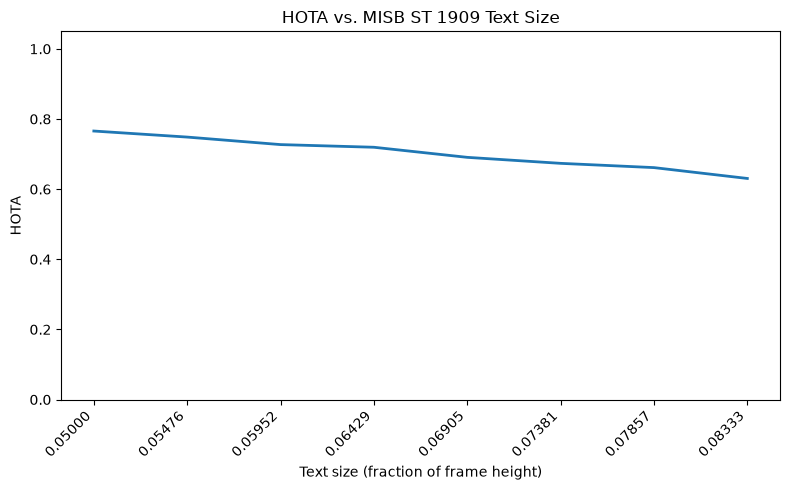

In [14]:
hota_values = [metrics["HOTA"] for metrics in perturbed_metrics]

plt.figure(figsize=(8, 5))
plt.plot(text_size_sweep, hota_values, linewidth=2)
plt.xlabel("Text size (fraction of frame height)")
plt.ylabel("HOTA")
plt.title("HOTA vs. MISB ST 1909 Text Size")
plt.xticks(text_size_sweep, rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Evaluation Interpretation

The baseline score is about 0.86. As we increase the text size we see a general decrease in HOTA, more of the text covers the scene and its vehicles, hurting track performance. At larger values the text blocks begin to overlap, which is not likely to happen in practice. Results on different scenes may differ due to scene content or generated metadata, so this should be viewed as a general performance trend rather than an absolute guarantee.

### Additional Plot

For further insight, we can plot the HOTA components separately.

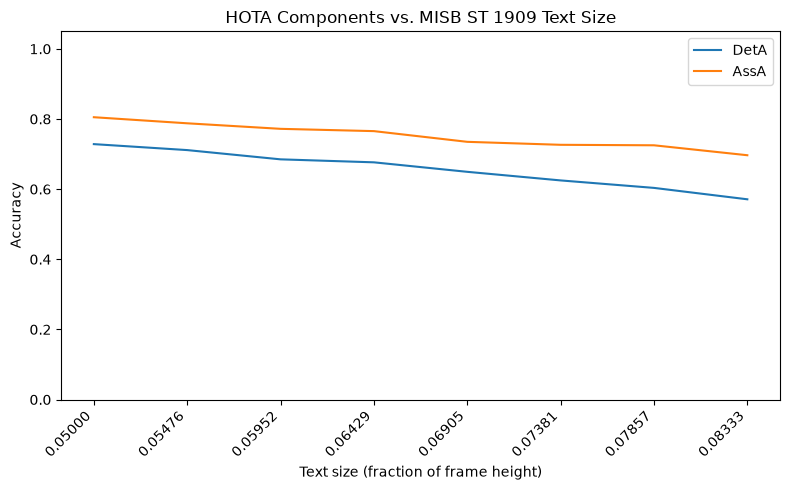

In [15]:
plt.figure(figsize=(8, 5))
plt.title("HOTA Components vs. MISB ST 1909 Text Size")
plt.xlabel("Text size (fraction of frame height)")
plt.ylabel("Accuracy")
for metric_name in ("DetA", "AssA"):
    plt.plot(
        text_size_sweep,
        [metrics[metric_name] for metrics in perturbed_metrics],
        label=metric_name,
    )
plt.xticks(text_size_sweep, rotation=45, ha="right")
plt.legend()
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

HOTA can be broken down into its two main components: Detection Accuracy (DetA) and Association Accuracy (AssA). DetA accounts for most of the loss, suggesting that burn-in mainly causes missed detections when text covers a vehicle, and tracking usually re-associates the vehicle once it moves past the text.

## End of Notebook